# BERT Sentiment Analysis + E-commerce App Reviews + ABSA



In [34]:

import sys
import subprocess

def run_pip(*packages):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *packages
    ])

print("1/3 Removing unused torchvision...")
subprocess.run(
    [sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchvision"],
    check=False
)

print("2/3 Installing stable NLP packages...")
run_pip(
    "transformers==4.46.3",
    "sentencepiece>=0.2.0",
    "spacy>=3.7,<4",
    "seaborn>=0.13",
    "matplotlib>=3.8",
    "pandas>=2.2,<3"
)

print("3/3 Installing spaCy English model...")
subprocess.check_call([
    sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"
])

print()
print("✅ Installation completed.")
print("🔄 IMPORTANT: Runtime → Restart session")
print("Then continue with Cell 2.")


1/3 Removing unused torchvision...
2/3 Installing stable NLP packages...
3/3 Installing spaCy English model...

✅ Installation completed.
🔄 IMPORTANT: Runtime → Restart session
Then continue with Cell 2.


In [35]:

# CELL 2 — Import and verify everything
# ============================================================

import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch
import transformers

from transformers import pipeline

print("✅ Environment loaded successfully!")
print()
print("Python       :", sys.version.split()[0])
print("PyTorch      :", torch.__version__)
print("Pandas       :", pd.__version__)
print("Transformers :", transformers.__version__)
print("spaCy        :", spacy.__version__)
print("GPU available:", torch.cuda.is_available())

# Load spaCy only after installation + restart.
nlp = spacy.load("en_core_web_sm")
print("spaCy model  : en_core_web_sm ✅")


✅ Environment loaded successfully!

Python       : 3.13.16
PyTorch      : 2.11.0+cpu
Pandas       : 2.2.3
Transformers : 4.46.3
spaCy        : 3.8.16
GPU available: False
spaCy model  : en_core_web_sm ✅


In [36]:

# CELL 3 — Test Transformers
# ============================================================

TEST_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"
DEVICE = 0 if torch.cuda.is_available() else -1

test_pipeline = pipeline(
    "sentiment-analysis",
    model=TEST_MODEL,
    device=DEVICE
)

result = test_pipeline("I love teaching artificial intelligence!")

print("✅ Transformers pipeline is working!")
print("Device:", "GPU" if DEVICE == 0 else "CPU")
print(result)


✅ Transformers pipeline is working!
Device: CPU
[{'label': 'POSITIVE', 'score': 0.9990171194076538}]


## CELL 3 — What is Sentiment Analysis?

Sentiment analysis tries to determine the emotional orientation of text.

Typical classes:

- 🟢 POSITIVE
- 🔴 NEGATIVE

Examples:

**"The app is easy to use." → POSITIVE**

**"The delivery arrived late." → NEGATIVE**

The interesting problem appears when a sentence contains more than one opinion.

In [37]:

# CELL 4 — Load a pretrained BERT sentiment model

MODEL_NAME = "textattack/bert-base-uncased-SST-2"
DEVICE = 0 if torch.cuda.is_available() else -1

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=DEVICE
)

print("✅ BERT sentiment model loaded!")
print("Model:", MODEL_NAME)
print("Device:", "GPU" if DEVICE == 0 else "CPU")


✅ BERT sentiment model loaded!
Model: textattack/bert-base-uncased-SST-2
Device: CPU


## CELL 5 — BERT Pipeline Concept

Conceptually:

**Text → Tokenizer → Token IDs → BERT → Classifier → Sentiment**

The next drawing is a teaching diagram, not the exact internal computation graph.

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128292 (\N{INPUT SYMBOL FOR LATIN LETTERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128290 (\N{INPUT SYMBOL FOR NUMBERS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


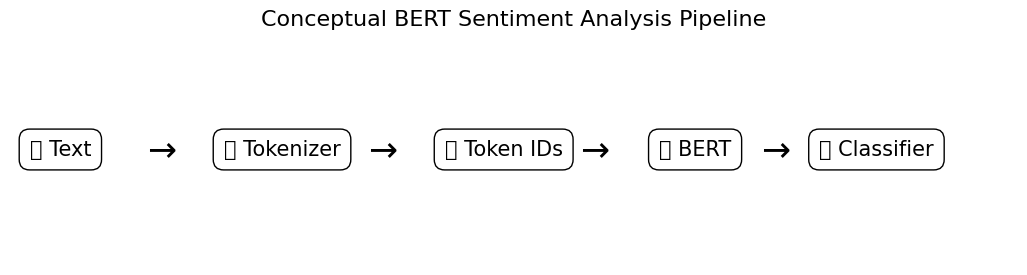

In [38]:
# CELL 6 — Draw the BERT sentiment pipeline

fig, ax = plt.subplots(figsize=(13, 3))
ax.axis("off")

boxes = [
    ("📝 Text", 0.05),
    ("🔤 Tokenizer", 0.27),
    ("🔢 Token IDs", 0.49),
    ("🧠 BERT", 0.68),
    ("🎯 Classifier", 0.86)
]

for label, x in boxes:
    ax.text(
        x, 0.5, label,
        ha="center", va="center", fontsize=15,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
    )

for x in [0.16, 0.38, 0.59, 0.77]:
    ax.annotate("→", xy=(x + 0.035, 0.5), xytext=(x - 0.01, 0.5),
                fontsize=25, ha="center", va="center")

plt.title("Conceptual BERT Sentiment Analysis Pipeline", fontsize=16)
plt.show()

In [39]:
# CELL 7 — Tokenization demonstration

tokenizer = sentiment_pipeline.tokenizer
text = "This shopping app makes ordering products easy!"

tokens = tokenizer.tokenize(text)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:")
print(text)

print("\nTokens:")
print(tokens)

print("\nToken IDs:")
print(token_ids)

print("\nSpecial-token version:")
print(tokenizer(text))

Original text:
This shopping app makes ordering products easy!

Tokens:
['this', 'shopping', 'app', 'makes', 'ordering', 'products', 'easy', '!']

Token IDs:
[2023, 6023, 10439, 3084, 13063, 3688, 3733, 999]

Special-token version:
{'input_ids': [101, 2023, 6023, 10439, 3084, 13063, 3688, 3733, 999, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## CELL 8 — Understanding the tokenizer

A tokenizer converts human language into units that the model can process.

BERT also uses special tokens such as:

- `[CLS]` — classification representation
- `[SEP]` — separates sequences
- `[PAD]` — padding when needed

The model ultimately processes numerical representations rather than raw English words.

In [40]:
# CELL 9 — First BERT prediction

sentence = "The delivery was fast and the packaging was excellent."

result = sentiment_pipeline(sentence)[0]

print("Sentence:", sentence)
print("Predicted sentiment:", result["label"])
print("Confidence:", f"{result['score']:.2%}")

Sentence: The delivery was fast and the packaging was excellent.
Predicted sentiment: LABEL_1
Confidence: 99.92%


In [41]:
# CELL 10 — Reusable prediction function

def explain_sentiment(text):
    prediction = sentiment_pipeline(text)[0]
    print("📝 Text:", text)
    print("🎯 Sentiment:", prediction["label"])
    print("📊 Confidence:", f"{prediction['score']:.2%}")
    return prediction

explain_sentiment("The movie was fantastic!")

📝 Text: The movie was fantastic!
🎯 Sentiment: LABEL_1
📊 Confidence: 99.97%


{'label': 'LABEL_1', 'score': 0.9996718168258667}

In [42]:
# CELL 11 — Classroom experiment

sentences = [
    "The app is easy to use.",
    "The delivery arrived late.",
    "The payment process was smooth.",
    "My refund has not arrived after a week.",
    "Customer support solved my issue quickly.",
    "The app crashed during checkout.",
    "The order tracking was clear and useful.",
    "The customer support agent was rude and unhelpful."
]

rows = []
for text in sentences:
    prediction = sentiment_pipeline(text)[0]
    rows.append({
        "Text": text,
        "Sentiment": prediction["label"],
        "Confidence": prediction["score"]
    })

classroom_df = pd.DataFrame(rows)
classroom_df["Confidence %"] = (classroom_df["Confidence"] * 100).round(2)

display(classroom_df[["Text", "Sentiment", "Confidence %"]])

,Text,Sentiment,Confidence %
0,The app is easy to use.,LABEL_1,99.56
1,The delivery arrived late.,LABEL_0,92.33
2,The payment process was smooth.,LABEL_1,99.54
3,My refund has not arrived after a week.,LABEL_0,96.76
4,Customer support solved my issue quickly.,LABEL_1,92.03
5,The app crashed during checkout.,LABEL_0,99.58
6,The order tracking was clear and useful.,LABEL_1,99.86
7,The customer support agent was rude and unhelp...,LABEL_0,99.82


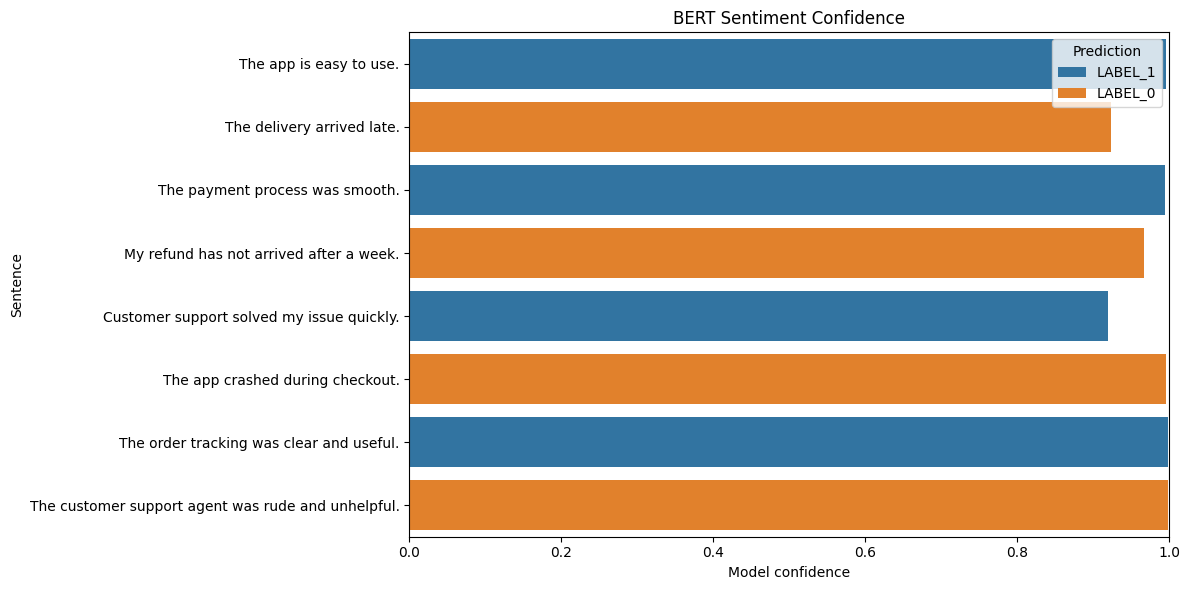

In [43]:

# CELL 12 — Confidence visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=classroom_df,
    x="Confidence",
    y="Text",
    hue="Sentiment",
    dodge=False
)

plt.xlim(0, 1)
plt.xlabel("Model confidence")
plt.ylabel("Sentence")
plt.title("BERT Sentiment Confidence")
plt.legend(title="Prediction")
plt.tight_layout()
plt.show()


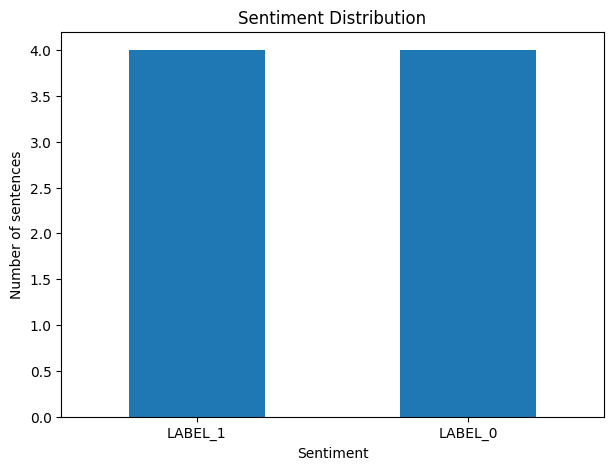

In [44]:
# CELL 13 — Positive vs Negative count

counts = classroom_df["Sentiment"].value_counts()

plt.figure(figsize=(7, 5))
counts.plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Number of sentences")
plt.title("Sentiment Distribution")
plt.xticks(rotation=0)
plt.show()

## CELL 14 — Why sentiment can be difficult

Consider:

> **"The delivery was excellent, but the refund process was awful."**

There are two opinions:

- Delivery → positive
- Service → negative

A standard binary sentiment classifier may still produce only one overall label.

Other difficult examples:

- Negation: "The app was not easy to use."
- Sarcasm: "Great! Another delayed delivery."
- Mixed sentiment: "I like the delivery speed but hate the refund process."
- Context: "The packaging is simple, but that is exactly what I wanted."

This motivates **Aspect-Based Sentiment Analysis (ABSA)**.

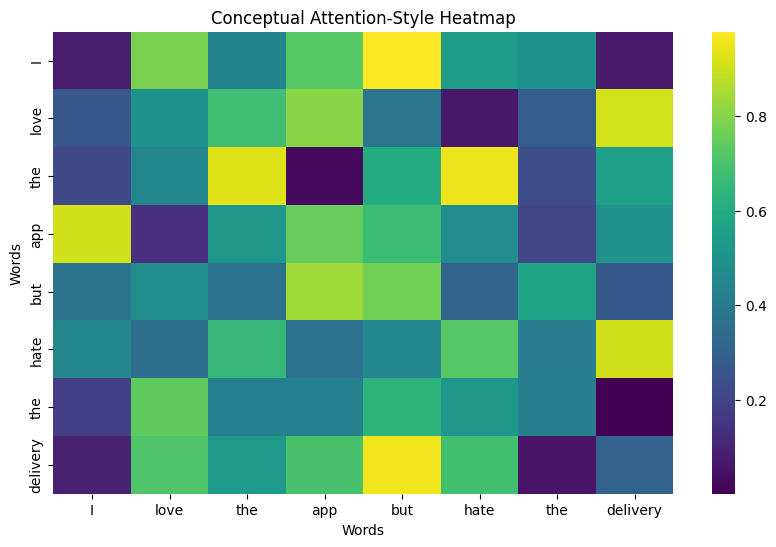

⚠️ Educational visualization only — not actual BERT attention weights.


In [45]:
# CELL 15 — Conceptual attention-style heatmap

# IMPORTANT:
# This is randomly generated for teaching.
# It is NOT the actual attention of the BERT model.

sentence = "I love the app but hate the delivery."
words = sentence.replace(".", "").split()

np.random.seed(7)
attention_demo = np.random.rand(len(words), len(words))

plt.figure(figsize=(10, 6))
sns.heatmap(
    attention_demo,
    xticklabels=words,
    yticklabels=words,
    cmap="viridis"
)

plt.title("Conceptual Attention-Style Heatmap")
plt.xlabel("Words")
plt.ylabel("Words")
plt.show()

print("⚠️ Educational visualization only — not actual BERT attention weights.")

In [46]:
# CELL 16 — Simplified BERT architecture

print("\n".join([
    "BERT-style architecture",
    "        ↓",
    "Input Text",
    "        ↓",
    "Tokenizer",
    "        ↓",
    "Token + Position Representations",
    "        ↓",
    "Transformer Encoder",
    "   ├── Self-Attention",
    "   ├── Feed-Forward Network",
    "   ├── Residual Connections",
    "   └── Layer Normalization",
    "        ↓",
    "Contextual Representation",
    "        ↓",
    "Classification Layer",
    "        ↓",
    "POSITIVE / NEGATIVE"
]))

BERT-style architecture
        ↓
Input Text
        ↓
Tokenizer
        ↓
Token + Position Representations
        ↓
Transformer Encoder
   ├── Self-Attention
   ├── Feed-Forward Network
   ├── Residual Connections
   └── Layer Normalization
        ↓
Contextual Representation
        ↓
Classification Layer
        ↓
POSITIVE / NEGATIVE


In [47]:
# CELL 17 — Count model parameters

total_params = sum(p.numel() for p in sentiment_pipeline.model.parameters())
trainable_params = sum(
    p.numel() for p in sentiment_pipeline.model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

print("\n💡 Teaching point:")
print("A pretrained transformer contains many learned parameters.")
print("We can reuse those learned representations instead of training from scratch.")

Total parameters: 109,483,778
Trainable parameters: 109,483,778

💡 Teaching point:
A pretrained transformer contains many learned parameters.
We can reuse those learned representations instead of training from scratch.


In [48]:
# CELL 18 — Tricky examples

tricky_sentences = [
    "I do not like this shopping app.",
    "The delivery speed is not bad.",
    "Great, another delayed delivery.",
    "I like the delivery speed but hate the refund process.",
    "The app was okay, nothing special.",
    "I expected better from such an expensive delivery delivery."
]

for text in tricky_sentences:
    prediction = sentiment_pipeline(text)[0]
    print(f"Text: {text}")
    print(f"Prediction: {prediction['label']} ({prediction['score']:.2%})")
    print("-" * 80)

Text: I do not like this shopping app.
Prediction: LABEL_0 (99.89%)
--------------------------------------------------------------------------------
Text: The delivery speed is not bad.
Prediction: LABEL_1 (99.94%)
--------------------------------------------------------------------------------
Text: Great, another delayed delivery.
Prediction: LABEL_0 (98.98%)
--------------------------------------------------------------------------------
Text: I like the delivery speed but hate the refund process.
Prediction: LABEL_0 (98.09%)
--------------------------------------------------------------------------------
Text: The app was okay, nothing special.
Prediction: LABEL_0 (98.36%)
--------------------------------------------------------------------------------
Text: I expected better from such an expensive delivery delivery.
Prediction: LABEL_0 (99.08%)
--------------------------------------------------------------------------------


# 🛒 CELL 19 — Mixed Reviews and the Need for ABSA

Consider:

> **"The delivery was quick, but the refund process was awful."**

A single overall sentiment label is not enough to explain the sentence.

| Aspect | Sentiment |
|---|---|
| delivery | ❤️ Positive |
| refund process | 💔 Negative |

This motivates **Aspect-Based Sentiment Analysis (ABSA)**.

ABSA asks:

> **What sentiment is expressed toward a particular aspect?**

Conceptually:

**Sentence + Aspect → Aspect Sentiment**

In [16]:

# CELL 20 — Load an ABSA model

# This model card documents text_pair usage for aspect-level sentiment.
ABSA_MODEL = "yangheng/deberta-v3-base-absa-v1.1"

absa_pipeline = pipeline(
    "text-classification",
    model=ABSA_MODEL,
    tokenizer=ABSA_MODEL,
    device=DEVICE
)

print("✅ ABSA model loaded!")
print("Model:", ABSA_MODEL)
print("Device:", "GPU" if DEVICE == 0 else "CPU")


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/738M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/18.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/convert_slow_tokenizer.py:561: UserWarning: The sentencepiece tokenizer that you are converting to a fast tokenizer uses the byte fallback option which is not implemented in the fast tokenizers. In practice this means that the fast version of the tokenizer can produce unknown tokens whereas the sentencepiece version would have converted these unknown tokens into a sequence of byte tokens matching the original piece of text.
  warnings.warn(


✅ ABSA model loaded!
Model: yangheng/deberta-v3-base-absa-v1.1
Device: CPU


In [17]:
# CELL 21 — First ABSA example

sentence = "The delivery was quick, but the refund process was awful."
aspects = ["delivery", "refund process"]

for aspect in aspects:
    result = absa_pipeline(sentence, text_pair=aspect)[0]
    print("Aspect:", aspect)
    print("Sentiment:", result["label"])
    print("Confidence:", f"{result['score']:.2%}")
    print("-" * 50)

Aspect: delivery
Sentiment: Positive
Confidence: 99.59%
--------------------------------------------------
Aspect: refund process
Sentiment: Negative
Confidence: 99.55%
--------------------------------------------------


## CELL 22 — Why provide an aspect?

Instead of asking:

> What is the sentiment of the whole sentence?

we ask:

> What is the sentiment with respect to **this aspect**?

For example:

`"The delivery was quick, but the refund process was awful." + "delivery" → Positive`

`"The delivery was quick, but the refund process was awful." + "refund process" → Negative`

In [18]:
# CELL 23 — Reusable ABSA function

def analyze_aspects(sentence, aspects):
    results = []

    for aspect in aspects:
        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(results)

sentence = "The delivery was quick, but the refund process was awful."
aspects = ["delivery", "refund process"]

result_df = analyze_aspects(sentence, aspects)
result_df["Confidence %"] = (result_df["Confidence"] * 100).round(2)

display(result_df[["Aspect", "Sentiment", "Confidence %"]])

,Aspect,Sentiment,Confidence %
0,delivery,Positive,99.59
1,refund process,Negative,99.55


In [19]:
# CELL 24 — Complex e-commerce review

sentence = (
    "The product selection is excellent, but delivery was late "
    "and the refund process is frustrating."
)

aspects = ["product selection", "delivery", "refund process", "customer support"]

review_df = analyze_aspects(sentence, aspects)
review_df["Confidence %"] = (review_df["Confidence"] * 100).round(2)

print("Review:")
print(sentence)
print()

display(review_df[["Aspect", "Sentiment", "Confidence %"]])

Review:
The product selection is excellent, but delivery was late and the refund process is frustrating.



,Aspect,Sentiment,Confidence %
0,product selection,Positive,99.67
1,delivery,Negative,99.72
2,refund process,Negative,99.72
3,customer support,Negative,98.09


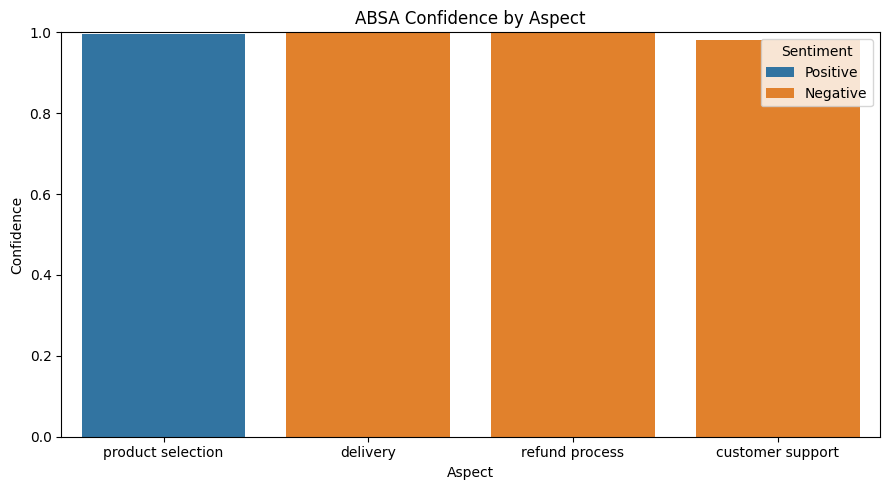

In [20]:

# CELL 25 — Aspect-level confidence visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=review_df,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.ylabel("Confidence")
plt.title("ABSA Confidence by Aspect")
plt.tight_layout()
plt.show()


In [21]:
# CELL 26 — Student prediction challenge

challenge_sentence = (
    "The product search is excellent, the checkout is confusing, "
    "and the delivery tracking is useful."
)

challenge_aspects = ["product search", "checkout", "delivery tracking"]

print("Read the review before running the model:")
print(challenge_sentence)
print()
print("Try to predict:")
print("product search → ?")
print("checkout → ?")
print("delivery tracking → ?")
print()

challenge_result = analyze_aspects(
    challenge_sentence,
    challenge_aspects
)

challenge_result["Confidence %"] = (
    challenge_result["Confidence"] * 100
).round(2)

display(challenge_result[["Aspect", "Sentiment", "Confidence %"]])

Read the review before running the model:
The product search is excellent, the checkout is confusing, and the delivery tracking is useful.

Try to predict:
product search → ?
checkout → ?
delivery tracking → ?



,Aspect,Sentiment,Confidence %
0,product search,Positive,99.73
1,checkout,Negative,99.51
2,delivery tracking,Positive,99.45


## CELL 27 — Interactive ABSA Classroom Demo

Type a review and provide aspects separated by commas.

Example:

Review:
`The app is fast but the refund process is disappointing.`

Aspects:
`app, refund process`

In [22]:
# CELL 28 — Interactive ABSA

sentence = input("📝 Enter a review: ")

aspects_input = input("🔍 Enter aspects separated by commas: ")

aspects = [
    aspect.strip()
    for aspect in aspects_input.split(",")
    if aspect.strip()
]

if not aspects:
    print("⚠️ Please enter at least one aspect.")
else:
    interactive_df = analyze_aspects(sentence, aspects)
    interactive_df["Confidence %"] = (
        interactive_df["Confidence"] * 100
    ).round(2)

    display(interactive_df[["Aspect", "Sentiment", "Confidence %"]])

📝 Enter a review: refund is slow
🔍 Enter aspects separated by commas: app,refund


,Aspect,Sentiment,Confidence %
0,app,Negative,97.92
1,refund,Negative,99.65


In [23]:
# CELL 29 — Standard BERT vs ABSA

sentence = "The delivery was quick, but the refund process was awful."

print("Sentence:")
print(sentence)

print("\n" + "=" * 70)
print("STANDARD BERT")
print("=" * 70)

overall = sentiment_pipeline(sentence)[0]

print("Overall sentiment:", overall["label"])
print("Confidence:", f"{overall['score']:.2%}")

print("\n" + "=" * 70)
print("ASPECT-BASED SENTIMENT ANALYSIS")
print("=" * 70)

comparison_df = analyze_aspects(sentence, ["delivery", "refund process"])
comparison_df["Confidence %"] = (
    comparison_df["Confidence"] * 100
).round(2)

display(comparison_df[["Aspect", "Sentiment", "Confidence %"]])

Sentence:
The delivery was quick, but the refund process was awful.

STANDARD BERT
Overall sentiment: LABEL_0
Confidence: 99.86%

ASPECT-BASED SENTIMENT ANALYSIS


,Aspect,Sentiment,Confidence %
0,delivery,Positive,99.59
1,refund process,Negative,99.55


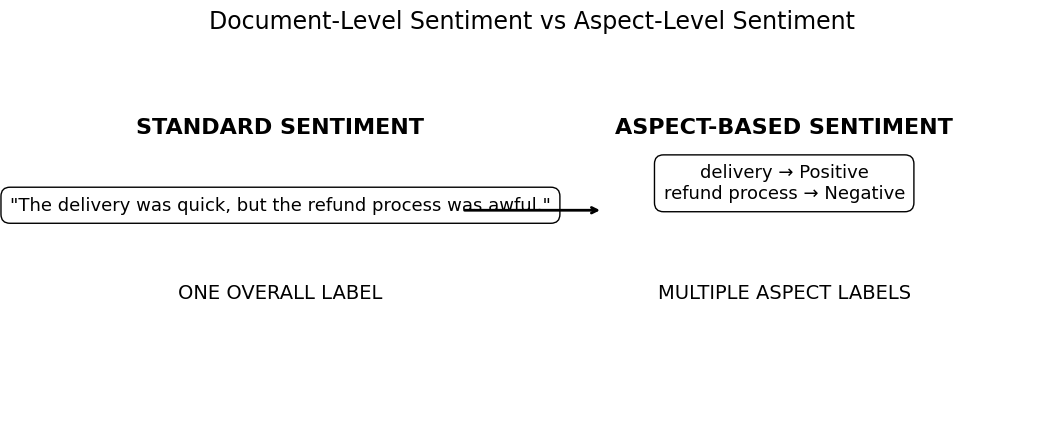

In [24]:
# CELL 30 — Visual comparison: document-level vs aspect-level

fig, ax = plt.subplots(figsize=(13, 5))
ax.axis("off")

ax.text(0.25, 0.75, "STANDARD SENTIMENT",
        ha="center", fontsize=16, fontweight="bold")

ax.text(
    0.25, 0.55,
    '"The delivery was quick, but the refund process was awful."',
    ha="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
)

ax.text(0.25, 0.32, "ONE OVERALL LABEL",
        ha="center", fontsize=14)

ax.text(0.75, 0.75, "ASPECT-BASED SENTIMENT",
        ha="center", fontsize=16, fontweight="bold")

ax.text(
    0.75, 0.58,
    "delivery → Positive\nrefund process → Negative",
    ha="center", fontsize=13,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
)

ax.text(0.75, 0.32, "MULTIPLE ASPECT LABELS",
        ha="center", fontsize=14)

ax.annotate("", xy=(0.57, 0.55), xytext=(0.43, 0.55),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.title("Document-Level Sentiment vs Aspect-Level Sentiment", fontsize=17)
plt.show()

# 🔎 CELL 31 — Simple Automatic Aspect Extraction

So far, we manually supplied aspects.

For teaching purposes, spaCy can find **nouns and proper nouns** as candidate aspects.

Examples:

- app
- delivery
- battery
- camera
- shopping app

⚠️ This is a simple educational heuristic, not a production-quality aspect extractor.

In [25]:

# CELL 32 — Verify the spaCy English model

print("spaCy pipeline:", nlp.pipe_names)
print("✅ spaCy English model is ready.")


spaCy pipeline: ['tok2vec', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
✅ spaCy English model is ready.


In [26]:
# CELL 33 — Extract candidate aspects

sentence = (
    "The product search is excellent, the checkout is confusing, "
    "and delivery tracking is useful."
)

doc = nlp(sentence)

possible_aspects = []

for token in doc:
    if token.pos_ in ["NOUN", "PROPN"]:
        if token.text.lower() not in [
            aspect.lower() for aspect in possible_aspects
        ]:
            possible_aspects.append(token.text)

print("Sentence:")
print(sentence)

print("\nCandidate aspects:")
print(possible_aspects)

Sentence:
The product search is excellent, the checkout is confusing, and delivery tracking is useful.

Candidate aspects:
['product', 'search', 'checkout', 'delivery', 'tracking']


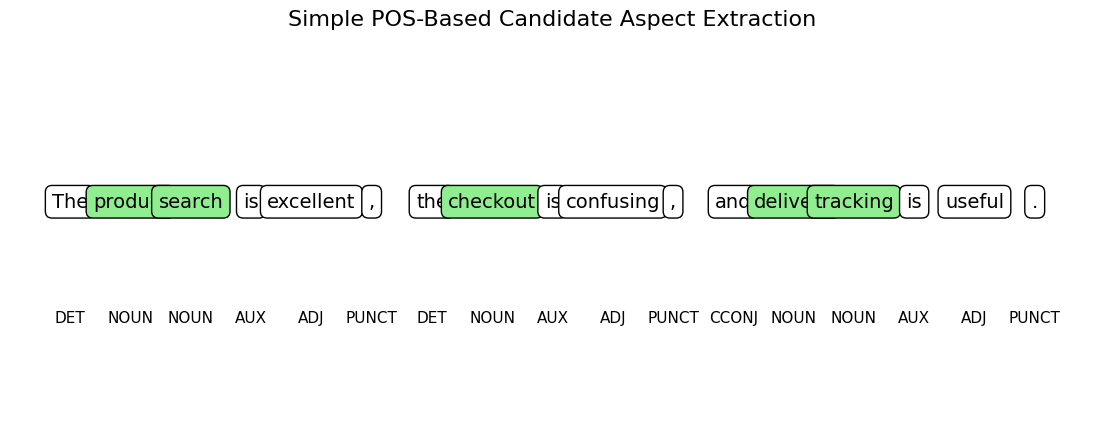

🟩 Green boxes = noun/proper-noun candidates


In [27]:
# CELL 34 — Visualize aspect extraction

doc = nlp(sentence)

words = [token.text for token in doc]
pos_tags = [token.pos_ for token in doc]

fig, ax = plt.subplots(figsize=(14, 5))
ax.axis("off")

for i, (word, pos) in enumerate(zip(words, pos_tags)):
    is_candidate = pos in ["NOUN", "PROPN"]

    ax.text(
        i, 0.55, word,
        ha="center", fontsize=14,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white" if not is_candidate else "lightgreen",
            edgecolor="black"
        )
    )

    ax.text(i, 0.25, pos, ha="center", fontsize=11)

ax.set_xlim(-1, len(words))
ax.set_ylim(0, 1)
ax.set_title("Simple POS-Based Candidate Aspect Extraction", fontsize=16)
plt.show()

print("🟩 Green boxes = noun/proper-noun candidates")

In [28]:

# CELL 35 — Automatic ABSA

def automatic_absa(sentence):
    """
    Educational automatic ABSA:
    1. Extract noun/proper-noun candidates with spaCy.
    2. Send each candidate as text_pair to the ABSA classifier.

    This is a classroom prototype, not a production-grade aspect extractor.
    """
    doc = nlp(sentence)

    aspects = []
    seen = set()

    for token in doc:
        if token.pos_ in ["NOUN", "PROPN"]:
            key = token.text.lower()
            if key not in seen:
                aspects.append(token.text)
                seen.add(key)

    results = []

    for aspect in aspects:
        prediction = absa_pipeline(
            sentence,
            text_pair=aspect
        )[0]

        results.append({
            "Aspect": aspect,
            "Sentiment": prediction["label"],
            "Confidence": prediction["score"]
        })

    return pd.DataFrame(
        results,
        columns=["Aspect", "Sentiment", "Confidence"]
    )

auto_result = automatic_absa(sentence)

if not auto_result.empty:
    auto_result["Confidence %"] = (
        auto_result["Confidence"] * 100
    ).round(2)
    display(auto_result[["Aspect", "Sentiment", "Confidence %"]])
else:
    print("No noun/proper-noun aspect candidates were found.")


,Aspect,Sentiment,Confidence %
0,product,Positive,98.98
1,search,Positive,99.63
2,checkout,Negative,99.55
3,delivery,Positive,99.25
4,tracking,Positive,99.17


In [29]:
# CELL 36 — Realistic mixed e-commerce review

product_review = (
    "The product search is excellent and checkout is simple, "
    "but delivery updates are confusing and customer support is unhelpful."
)

print("Review:")
print(product_review)

product_result = automatic_absa(product_review)

if len(product_result) > 0:
    product_result["Confidence %"] = (
        product_result["Confidence"] * 100
    ).round(2)

display(product_result[["Aspect", "Sentiment", "Confidence %"]])

Review:
The product search is excellent and checkout is simple, but delivery updates are confusing and customer support is unhelpful.


,Aspect,Sentiment,Confidence %
0,product,Positive,99.45
1,search,Positive,99.68
2,checkout,Positive,99.21
3,delivery,Negative,99.68
4,updates,Negative,99.65
5,customer,Negative,99.55
6,support,Negative,99.56


In [30]:
# CELL 37 — Manual aspects can be more precise

manual_aspects = [
    "product search",
    "checkout",
    "delivery updates",
    "customer support"
]

manual_result = analyze_aspects(
    product_review,
    manual_aspects
)

manual_result["Confidence %"] = (
    manual_result["Confidence"] * 100
).round(2)

display(manual_result[["Aspect", "Sentiment", "Confidence %"]])

,Aspect,Sentiment,Confidence %
0,product search,Positive,99.71
1,checkout,Positive,99.21
2,delivery updates,Negative,99.64
3,customer support,Negative,99.55


## CELL 38 — Complete ABSA pipeline

A practical ABSA system can be understood as:

**Review**
↓
**Aspect Extraction**
↓
**Aspect Identification**
↓
**Aspect Sentiment Classification**
↓
**Structured Output / Dashboard**

Example:

```text
"The product search is excellent but the refund process is terrible."

product search → positive
refund process → negative
```

The aspect-extraction and sentiment-classification steps can be separate components.

In [31]:
# CELL 39 — Final ABSA dashboard

final_review = (
    "The product selection is excellent, delivery was quick, "
    "but the refund process was slow and customer support was unhelpful."
)

final_aspects = ["product selection", "delivery", "refund process", "customer support"]

final_result = analyze_aspects(
    final_review,
    final_aspects
)

final_result["Confidence %"] = (
    final_result["Confidence"] * 100
).round(2)

print("📝 FINAL REVIEW")
print(final_review)

display(final_result[["Aspect", "Sentiment", "Confidence %"]])

📝 FINAL REVIEW
The product selection is excellent, delivery was quick, but the refund process was slow and customer support was unhelpful.


,Aspect,Sentiment,Confidence %
0,product selection,Positive,99.69
1,delivery,Positive,99.56
2,refund process,Negative,99.68
3,customer support,Negative,99.53


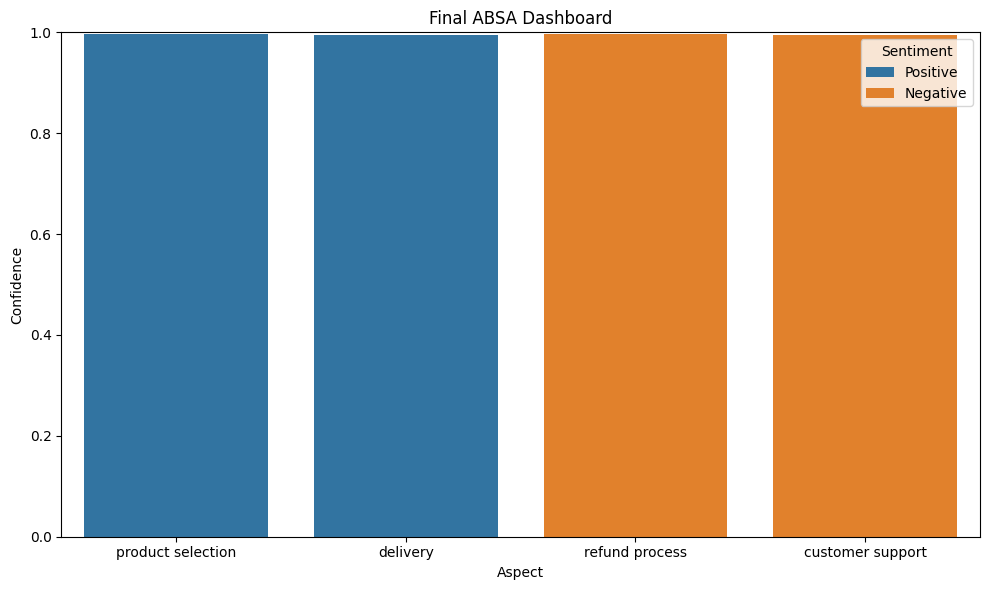

In [32]:

# CELL 40 — Final dashboard visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_result,
    x="Aspect",
    y="Confidence",
    hue="Sentiment",
    dodge=False
)

plt.ylim(0, 1)
plt.xlabel("Aspect")
plt.ylabel("Confidence")
plt.title("Final ABSA Dashboard")
plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


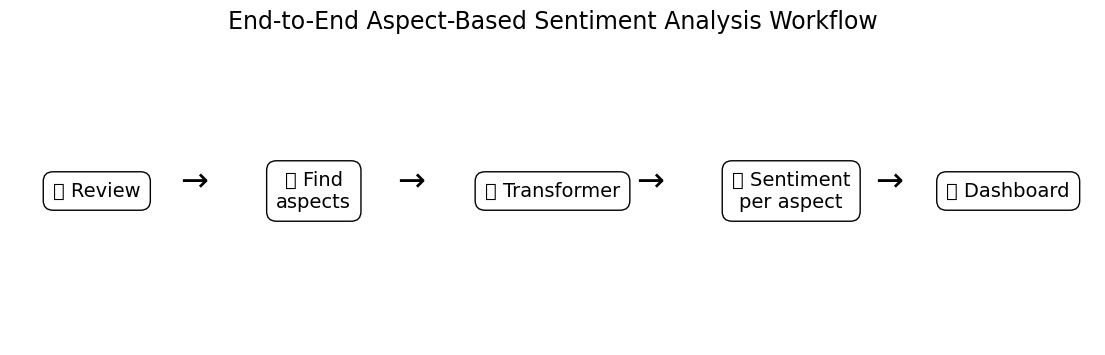

In [33]:
# CELL 41 — End-to-end workflow drawing

fig, ax = plt.subplots(figsize=(14, 4))
ax.axis("off")

steps = [
    ("📝 Review", 0.08),
    ("🔍 Find\naspects", 0.28),
    ("🧠 Transformer", 0.50),
    ("🎯 Sentiment\nper aspect", 0.72),
    ("📊 Dashboard", 0.92)
]

for label, x in steps:
    ax.text(
        x, 0.5, label,
        ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black")
    )

for x in [0.18, 0.38, 0.60, 0.82]:
    ax.annotate("→", xy=(x + 0.035, 0.5), xytext=(x - 0.01, 0.5),
                fontsize=24, ha="center")

plt.title("End-to-End Aspect-Based Sentiment Analysis Workflow", fontsize=17)
plt.show()